# FITS File Creation & Verification Notebook
**Project:** Astronomical Image Data Matrix Compilation  
**Objective:** Porting legacy C CFITSIO linear ramp operations to optimized Python code.

This notebook establishes an automated pipeline to construct `.fits` file types, assign appropriate headers, and visually verify dataset arrays.

### Step 1: Initialize Project Environment
Ensure your system has the proper astronomy computing environments installed.

In [1]:
!pip install astropy numpy matplotlib

### Step 2: Import Core Modules & Configuration
Define explicit pixel matrices matching your core data dimensions ($300 \times 200$ array dimensions).

In [2]:
import astropy.io.fits as fits
import matplotlib.pyplot as plt
import numpy as np

# Set the original structural parameters
width = 300
height = 200

### Step 3: Array Initialization & Matrix Generation
Vectorized representation of the original programmatic ramp function `array[jj][ii] = ii + jj` using NumPy index spaces.

In [3]:
# Construct index arrays for structural height and width dimensions
jj, ii = np.indices((height, width))
data_array = (ii + jj).astype(np.int16)  # Replicates SHORT_IMG pixel structure

print(f"Data array constructed successfully with matrix shape: {data_array.shape}")

Data array constructed successfully with matrix shape: (200, 300)


### Step 4: Construct FITS HDU & File Output
Wrap raw arrays into Primary Header Data Units (HDUs) and commit metadata headers to disk storage.

In [4]:
# Instantiate primary header data unit wrapper
hdu = fits.PrimaryHDU(data=data_array)

# Insert explicit science metrics tracking metadata keys
hdu.header["EXPOSURE"] = (1500, "Total Exposure Time")

# Dynamically compute and inject CHECKSUM and DATASUM keys
hdu.ad

# Serialize the complete entity matrix payload to a persistent file structure
output_filename = "demo_image.fits"
hdu.writeto(output_filename, overwrite=True)

print(f"Target FITS structure written successfully to disk location: {output_filename}")

Target FITS structure written successfully to disk location: demo_image.fits


### Step 5: Readback & Quality Assurance Plotting
Re-open files from storage to read back parameters and visualize arrays.

--- COMPILED FITS METADATA DATASET ---

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  300                                                  
NAXIS2  =                  200                                                  
EXTEND  =                    T                                                  
EXPOSURE=                 1500 / Total Exposure Time                            


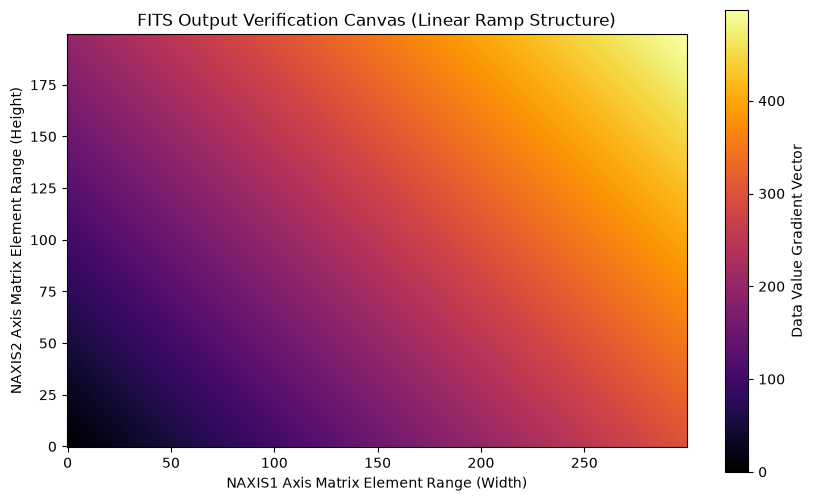

In [5]:
# Open the freshly minted asset interface
with fits.open("demo_image.fits") as hdul:
    print("--- COMPILED FITS METADATA DATASET ---\n")
    print(repr(hdul[0].header))
    
    # Visual confirmation plot mapping matrices
    plt.figure(figsize=(10, 6))
    plt.imshow(hdul[0].data, cmap="inferno", origin="lower")
    plt.colorbar(label="Data Value Gradient Vector")
    plt.title("FITS Output Verification Canvas (Linear Ramp Structure)")
    plt.xlabel("NAXIS1 Axis Matrix Element Range (Width)")
    plt.ylabel("NAXIS2 Axis Matrix Element Range (Height)")
    plt.show()